# Does the cleaner work on the experiments of the Dipole-lets paper plots? (generalization check)

Same experiments as `utils/Dipole-lets_Paper_Plots_3.ipynb` (cell 6: `exp1` ... `exp11`, same positions, same seed 47), plus the Sim2 ground truth forward-simulated and corrupted with the notebook's complex-noise recipe. Every volume is shown with `imagesc3d2` and every error with `compute_rmse`, as in the original.

**Read this before the numbers**

* **RC1 experiments are NOT an independent test.** The nets were trained on this very head (patches from x in [0,100) of axis 0, plus rotated/rescaled copies) with random placements of the same artifact families. The only held-out part is the check slab x in [112,160), and even there the net saw the dipole field of the whole head in the original pose. `exp7` (in-vivo tissue phase), `exp8`, `exp9` use real residuals that only the `mix` net was trained on; `noise` never saw them.
* **Forward-simulated Sim2 is a test of the anatomy, not of the artifacts**: the head was never trained on, but its inputs contain only the synthetic noise (the real Sim2 `psi` is not in them).
* Two conventions for the field **outside the brain mask**: `clean` = noise-free `D*chi` there (what the nets saw in training) and `out0` = zeros (what `Frequency.nii` and a BET-masked in-vivo field look like). A large gap between them means the nets use the outside field, which does not exist in real data.
* Targets are always `mask * D*chi` (COSMOS for RC1, ground truth for Sim2). eNDI = `ndiCG_auto`, alpha 1e-5, linear, 150 iterations max, zero-padded to 192^3 (RC1) or 256^3 (Sim2).

Data: made on the server by `scripts/export_generalization.py` (the cleaning and the inversions need the GPU); copy `runs/generalization/` to the PC.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({         # Global font size, as in the paper notebook
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})

here = [Path.cwd(), *Path.cwd().parents]
def find(*rel):
    for base in here:
        for r in rel:
            if (base / r).exists():
                return base / r
    raise FileNotFoundError(f"none of {rel} found from {Path.cwd()} or its parents")
sys.path.insert(0, str(find("external/FANSI_tools.py", "utils/FANSI_tools.py", "FANSI_tools.py").parent))
from FANSI_tools import imagesc3d2, compute_rmse     # the user's own plotting / RMSE functions
GEN = find("runs/generalization")
print("data:", GEN)

data: c:\Users\ignac\OneDrive\Desktop\Projects\Research\2025\QSM\DipoleNet\MCNO-QSM\runs\generalization


In [2]:
def load_set(tag):
    common = np.load(GEN / f"{tag}_common.npz")
    common = {k: common[k].astype(np.float32) if common[k].ndim == 3 else common[k] for k in common.files}
    meta = json.loads((GEN / f"{tag}_meta.json").read_text())
    return common, meta

def load_exp(tag, name):
    z = np.load(GEN / f"{tag}_{name}.npz")
    return {k: z[k].astype(np.float32) for k in z.files}

def view(vol, title, contrast, rot, pos=None):
    # same call as the paper notebook: three planes through the centre, grey, shared contrast
    pos = tuple(x // 2 for x in vol.shape) if pos is None else pos
    imagesc3d2(vol, pos, cmap='grey', contrast=contrast, fig_num=2, rot_deg=rot, scale_fig=[-0.12, 0.12, -0.12, 0.12],
               avg_size=0, title_fig=title)

ROT_RC1 = [90, 90, -90]      # cells 7 / 17 of the paper notebook (RC1 views)
ROT_SIM2 = [90, 90, 90]      # cells 11 / 13 (Sim2 views)
FIELD = [-0.03, 0.03]        # ppm, field images
ERR = [-0.015, 0.015]
CHI = [-0.1, 0.1]            # ppm, susceptibility maps (as the paper notebook)
CHI_ERR = [-0.05, 0.05]

SETS = {}
for tag in ("rc1", "sim2"):
    try:
        SETS[tag] = load_set(tag)
        print(tag, "experiments:", [k for k in SETS[tag][1] if k != "oracle"])
    except FileNotFoundError as e:
        print("missing", tag, e)

rc1 experiments: ['exp1', 'exp2', 'exp3', 'exp4', 'exp5', 'exp6', 'exp7', 'exp8', 'exp9', 'exp10', 'exp11']
sim2 experiments: ['sim2_snr100', 'sim2_snr40', 'sim2_snrcal', 'sim2_jumps', 'sim2_spheres']


In [3]:
def table(tag, region="all"):
    common, meta = SETS[tag]
    exps = [k for k in meta if k != "oracle"]
    methods = list(meta[exps[0]]["methods"])
    key = f"phase_nrmse_{region}"
    print(f"phase NRMSE (%) vs mask*D*chi, region = {region}")
    print(f"{'experiment':14s}" + "".join(f"{m:>12s}" for m in methods))
    for e in exps:
        print(f"{e:14s}" + "".join(f"{meta[e]['methods'][m].get(key, float('nan')):12.2f}" for m in methods))
    print()
    print("eNDI NRMSE (%) vs chi ground truth" + (f"   (oracle mask*D*chi: {meta['oracle']['nrmse']:.2f}%)" if "oracle" in meta else ""))
    print(f"{'experiment':14s}" + "".join(f"{m:>12s}" for m in methods))
    for e in exps:
        print(f"{e:14s}" + "".join(f"{meta[e]['methods'][m].get('endi_nrmse', float('nan')):12.2f}" for m in methods))

## A. Paper experiments on RC1 (exp1 ... exp11)

Phase NRMSE: distance of each field to the target `mask * D*chi_cosmos` (dirty = the experiment itself, masked). Columns ending in `_out0` use zeros outside the mask. The `check` table covers only the held-out slab x in [112,160). Where the cleaner is useful, the number falls; for `exp1` / `exp10` (nothing to remove) any change is a harm.

In [4]:
if "rc1" in SETS:
    table("rc1", "all"); print("=" * 90); table("rc1", "check")

phase NRMSE (%) vs mask*D*chi, region = all
experiment           dirty       noise  noise_out0         mix    mix_out0
exp1                  0.00       10.85       11.45       12.29       12.88
exp2                 15.45       12.83       13.36       14.47       14.97
exp3                 38.63       18.80       19.20       20.08       20.46
exp4                 52.02       14.54       15.00       12.57       13.15
exp5                348.51      326.95      326.97       23.81       24.12
exp6                112.35      104.27      104.33       14.32       14.83
exp7                 73.58       54.79       54.87       48.93       48.97
exp8                 45.23       39.28       39.36       35.26       35.25
exp9                 63.83       56.10       56.03       50.16       49.99
exp10                 0.00       10.85       11.45       12.29       12.88
exp11                50.78       37.20       37.40       20.91       21.27

eNDI NRMSE (%) vs chi ground truth   (oracle mask*D*chi

### A.1 Fields: dirty, cleaned, and what remains (RC1)

For each experiment: the dirty field (ppm), the cleaned field, and `cleaned - target`. Same grey scale and plane rotation as the paper notebook.

exp2 noise SNR 100


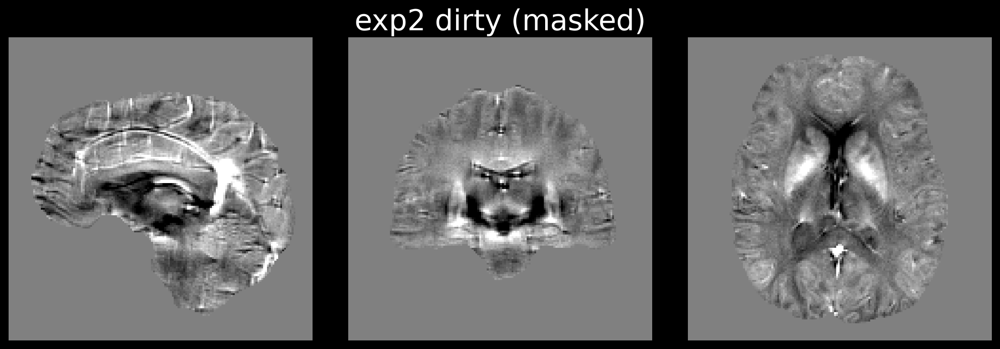

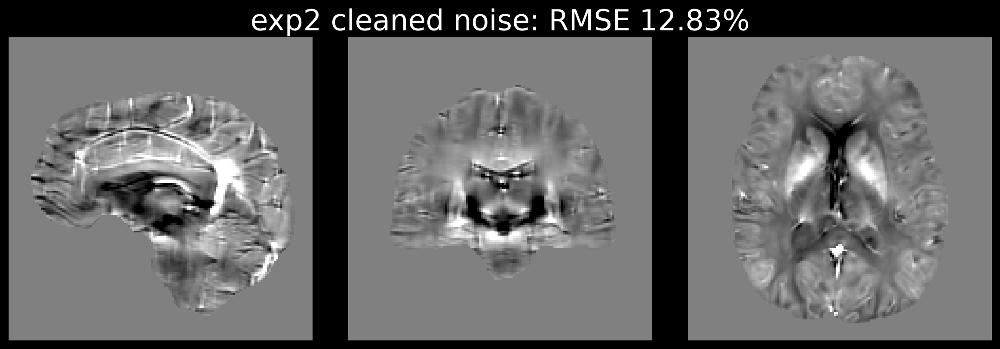

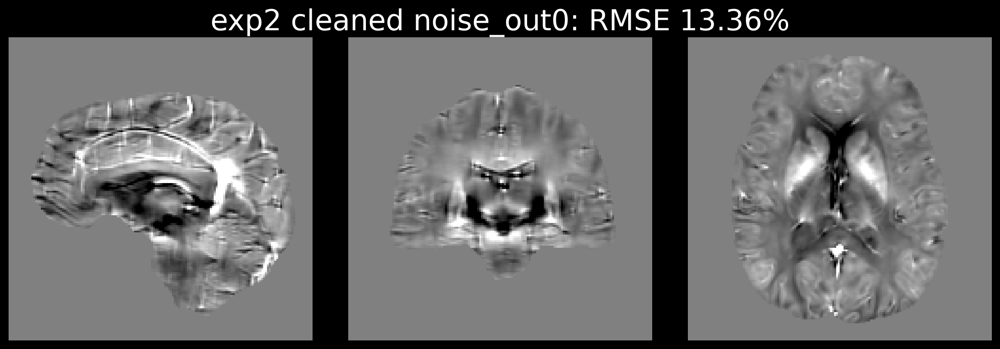

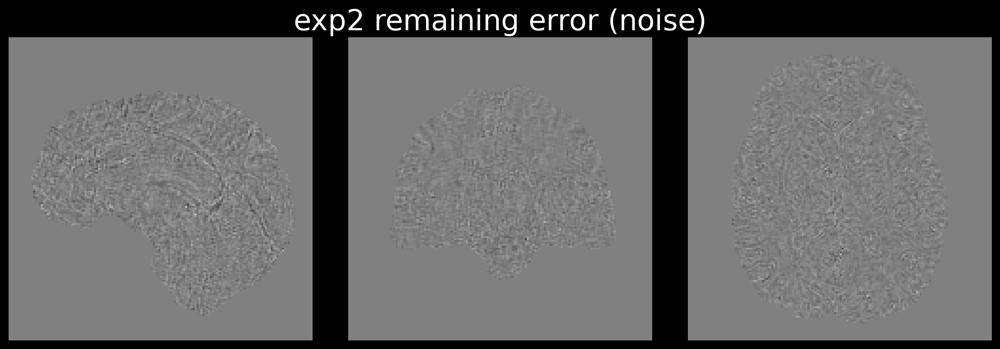

exp3 noise SNR 40


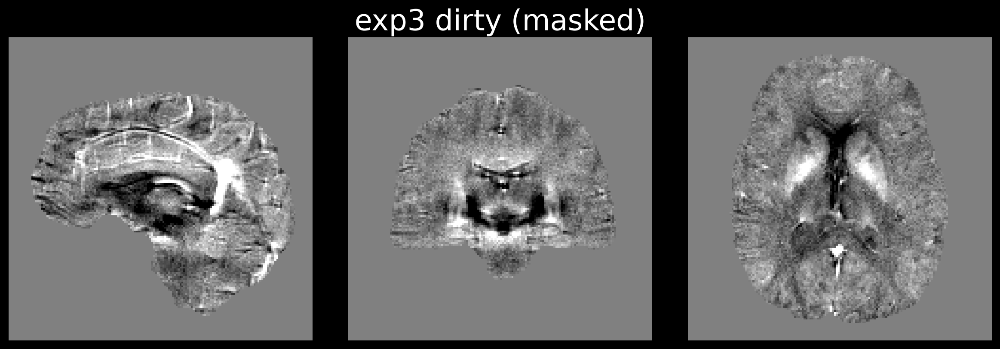

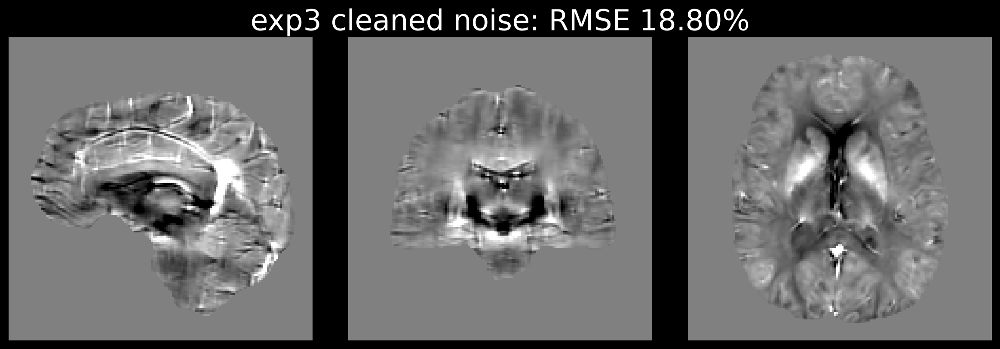

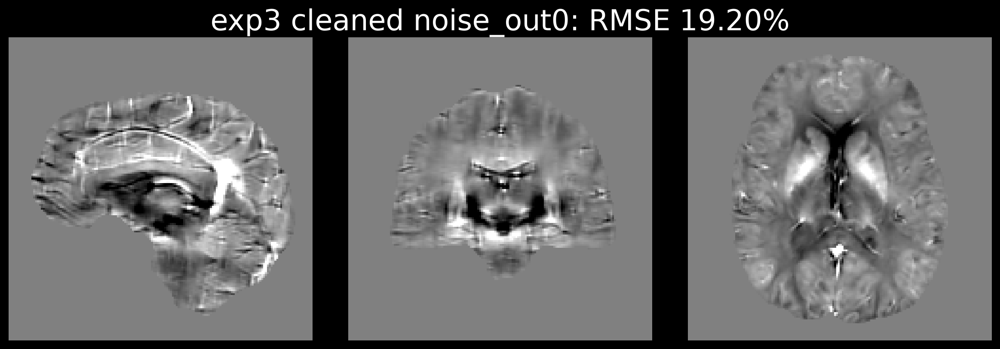

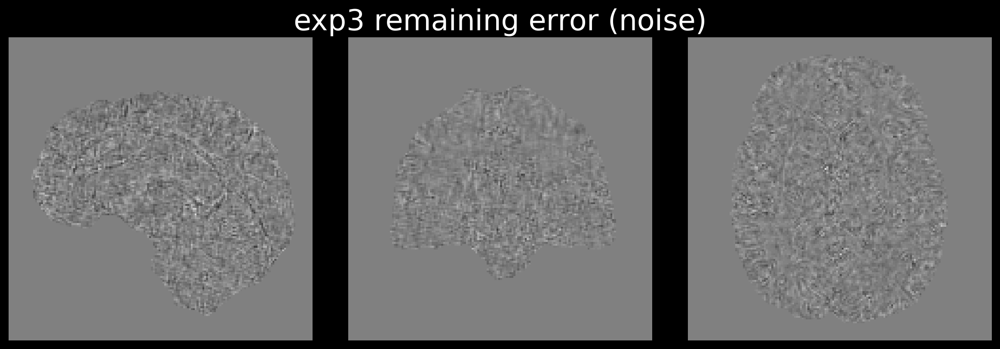

exp4 phase jumps


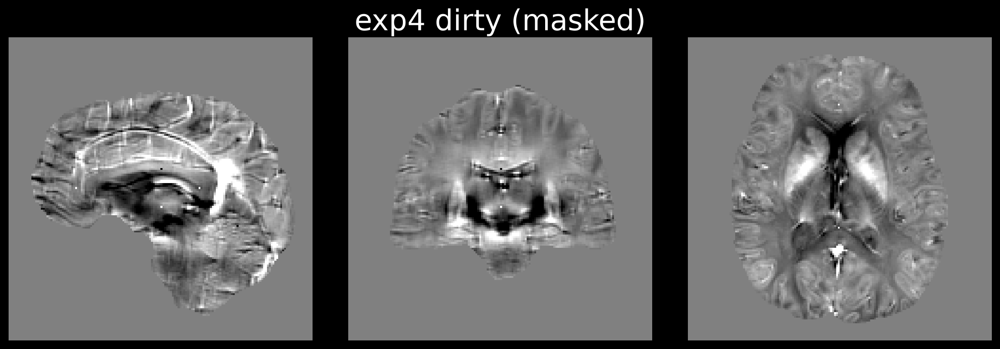

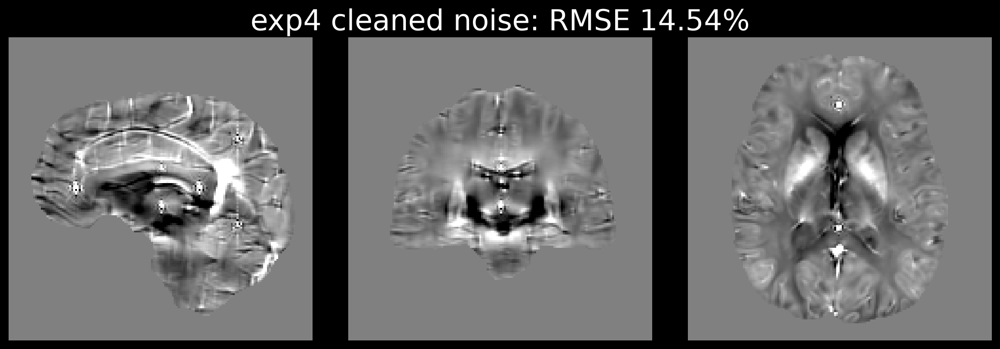

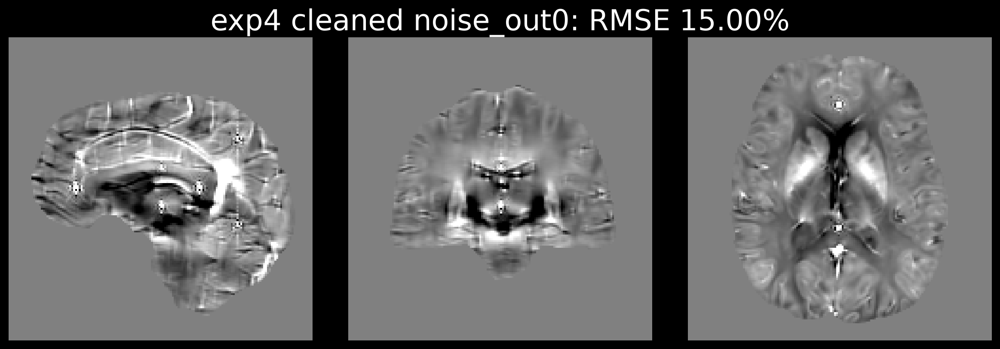

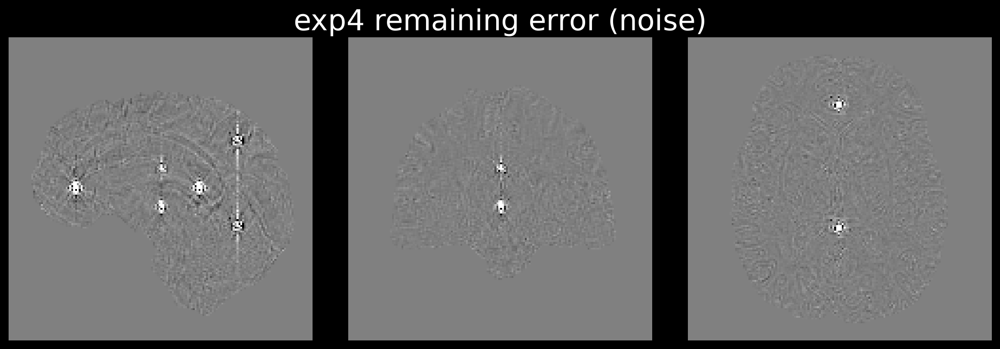

exp5 cylinders


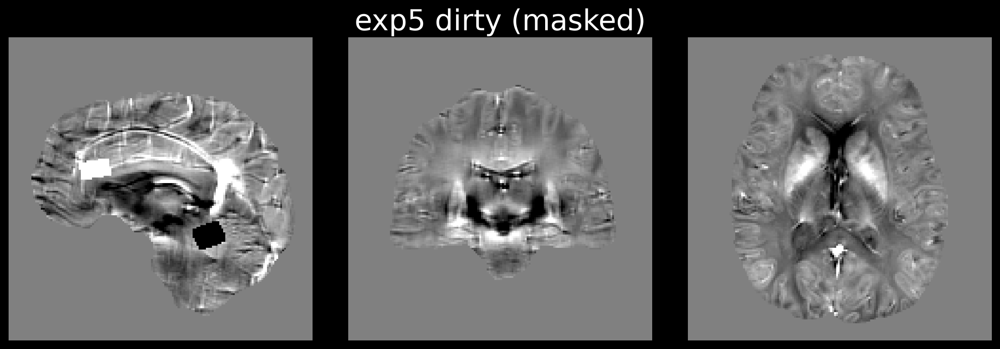

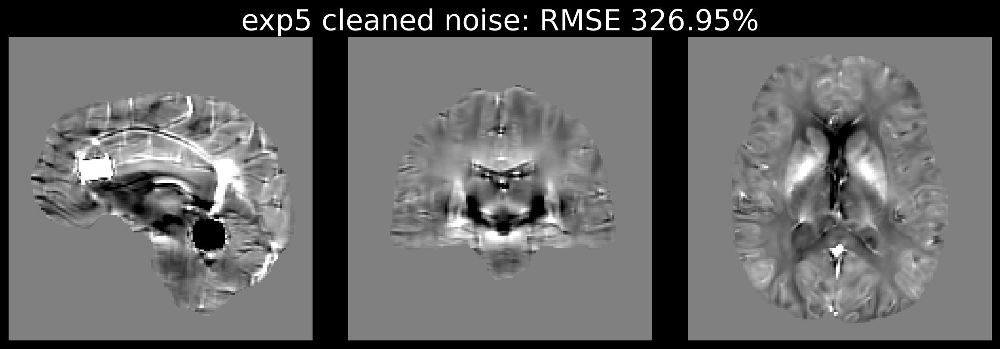

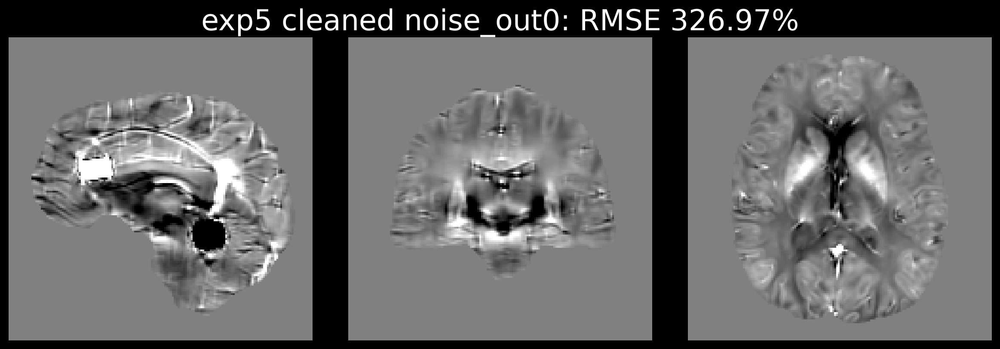

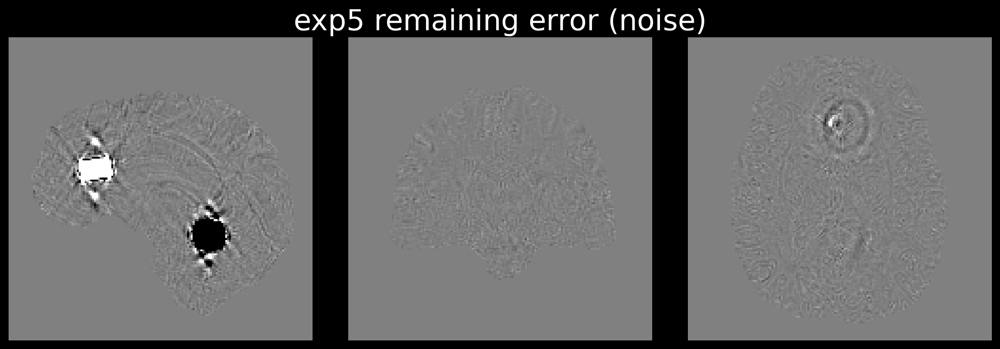

exp6 spheres (phase)


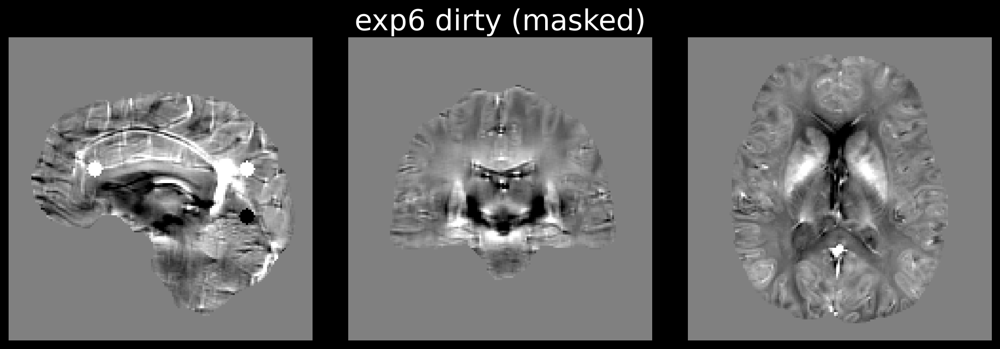

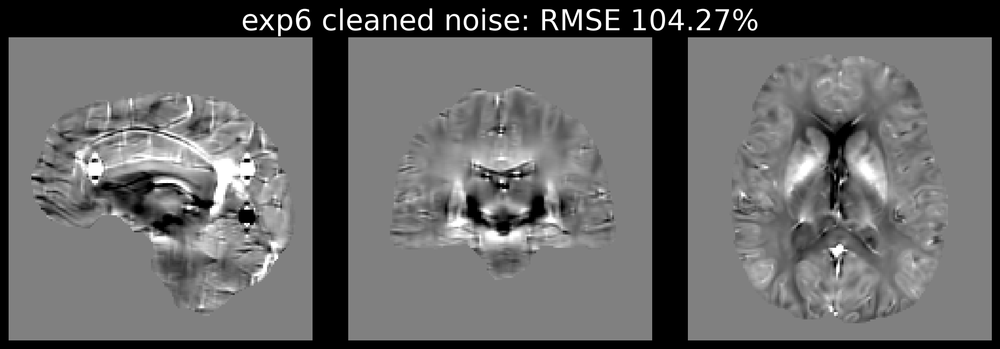

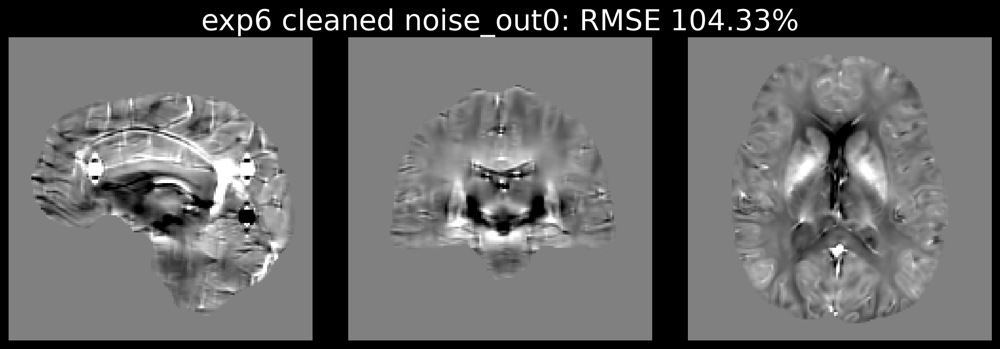

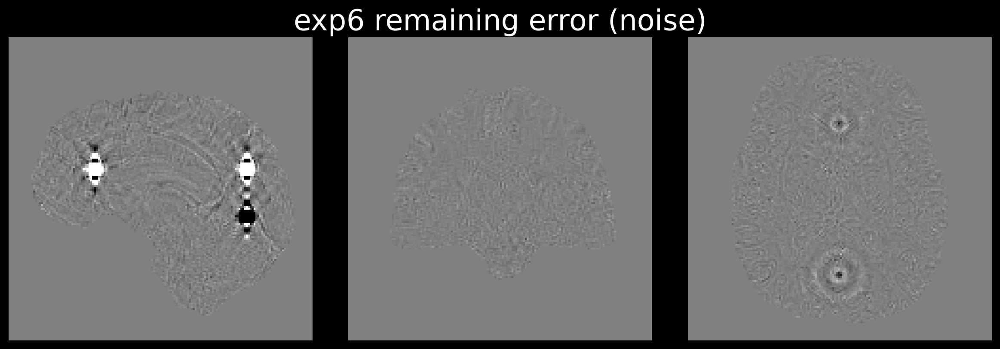

exp7 in vivo phs_tissue


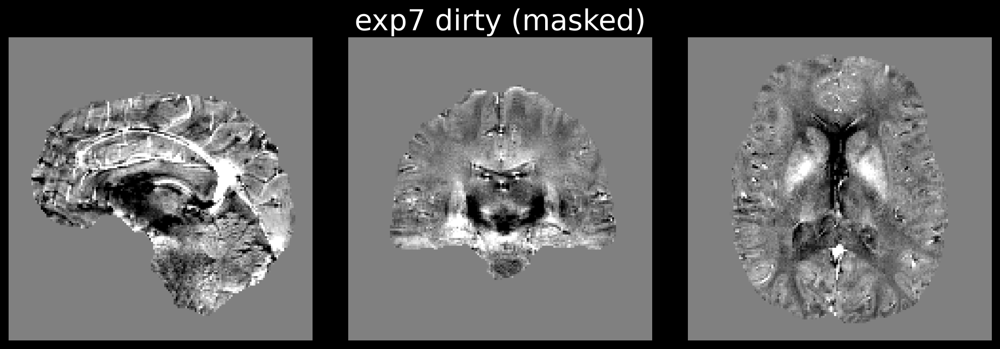

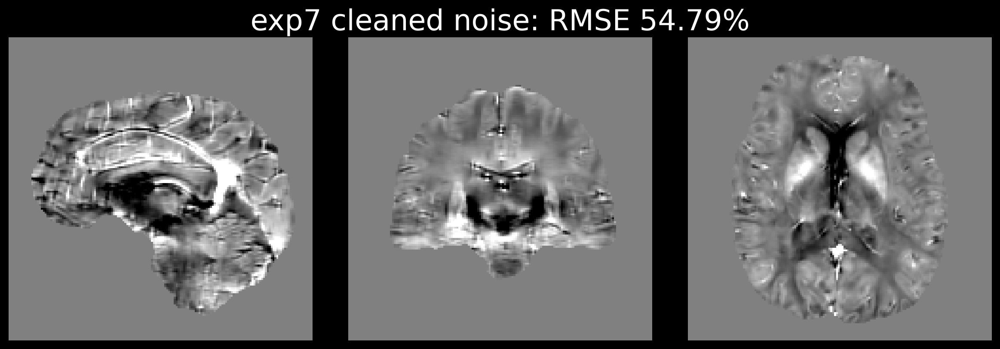

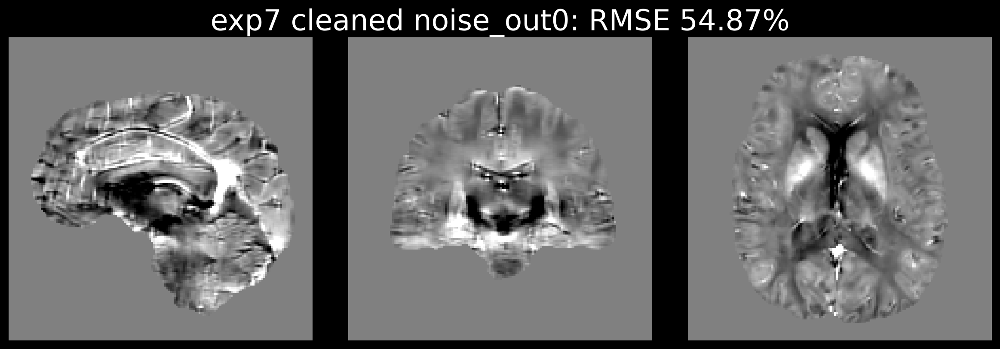

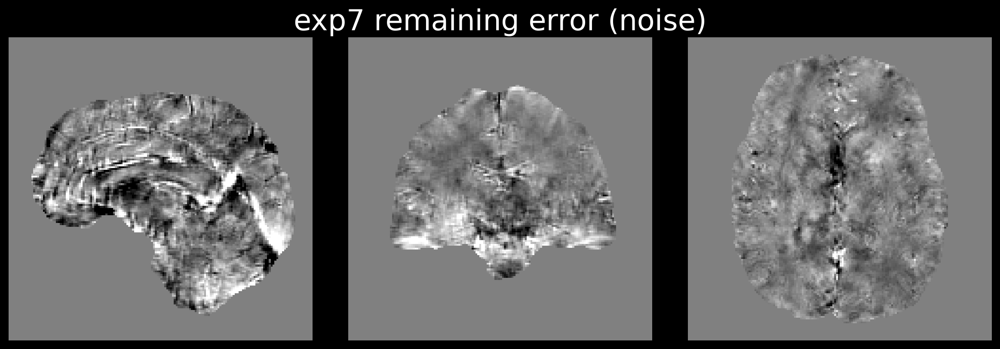

exp8 STI


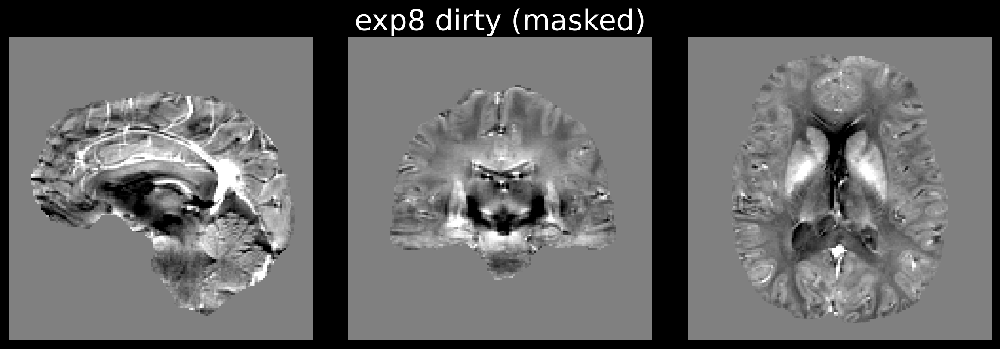

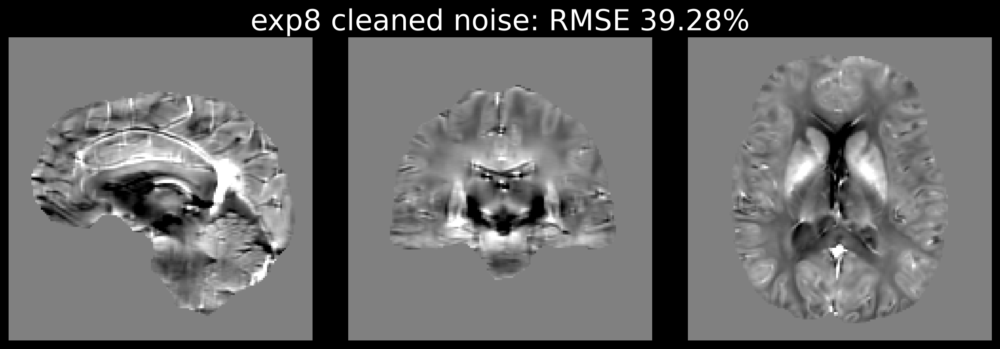

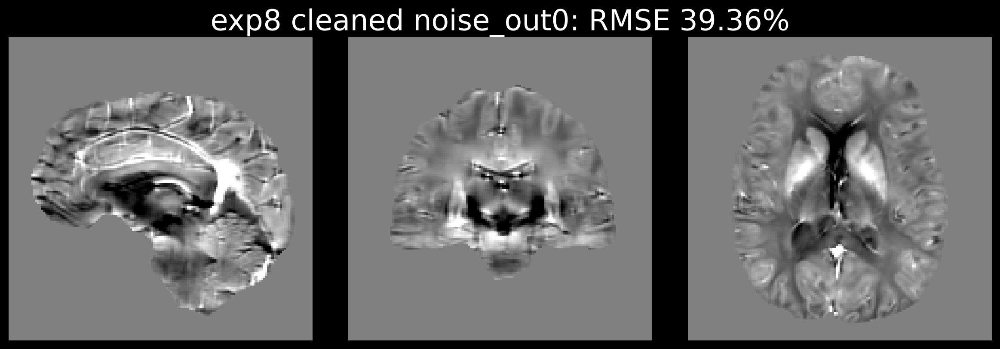

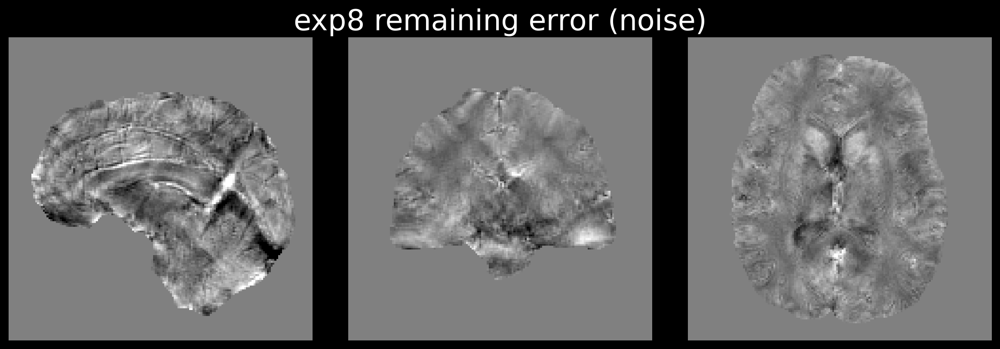

exp9 off-diagonal (clean - pQ)


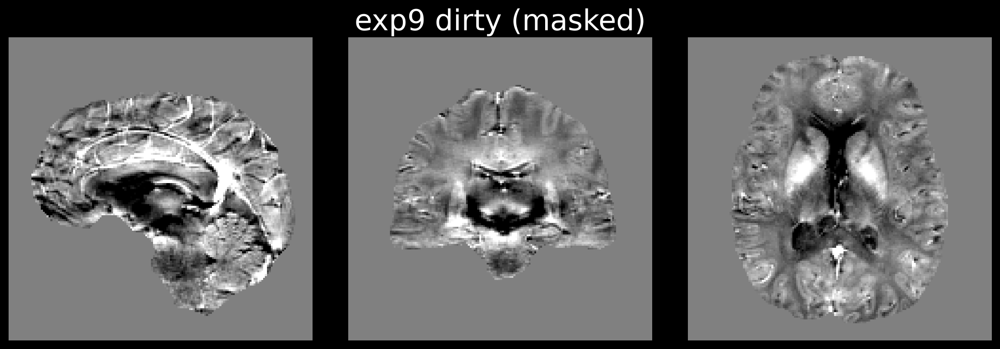

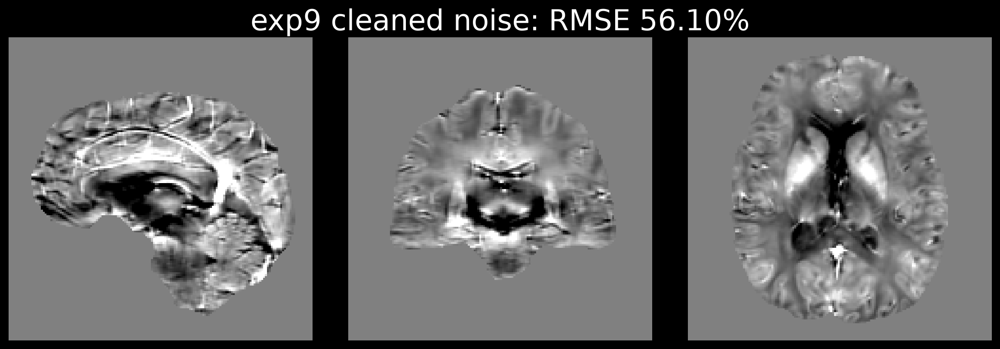

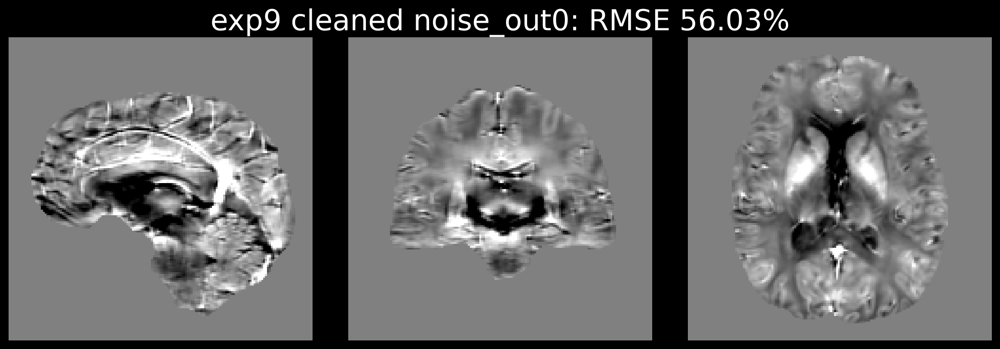

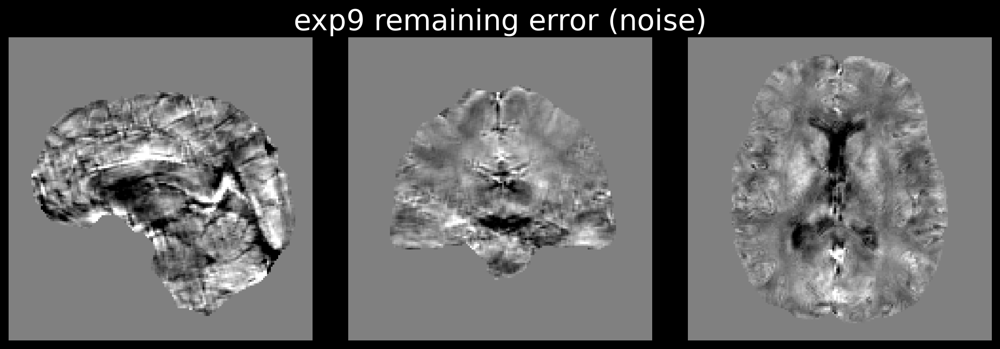

exp11 spheres in chi + noise SNR 40


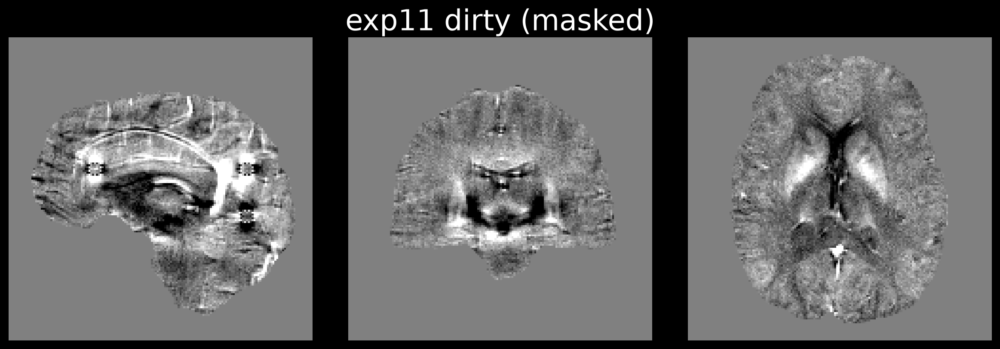

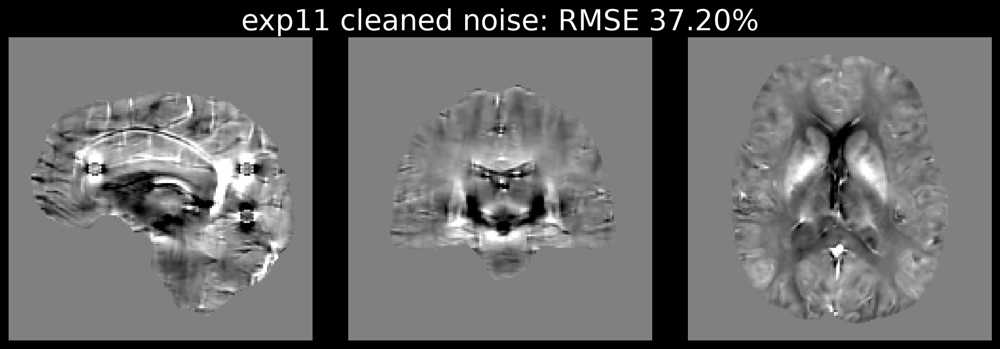

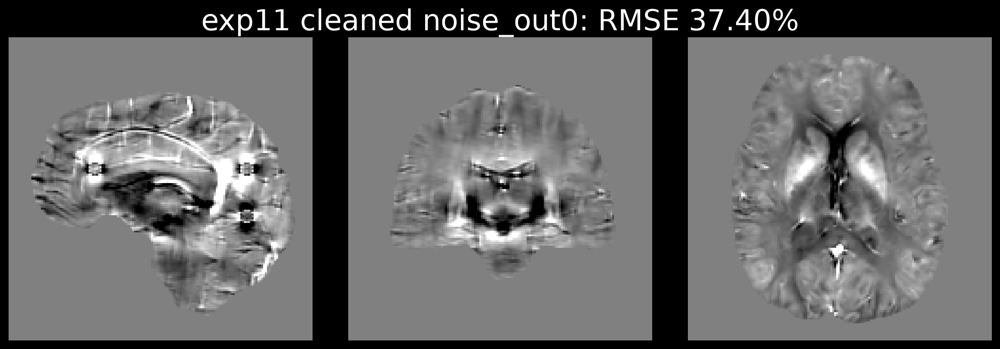

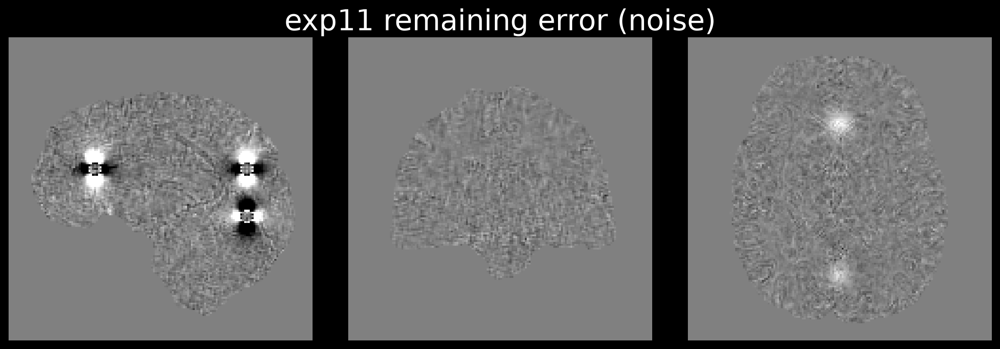

In [5]:
EXPS_RC1 = ["exp2", "exp3", "exp4", "exp5", "exp6", "exp7", "exp8", "exp9", "exp11"]   # edit to look at others
MAIN = "noise"                                                                          # which run to display
if "rc1" in SETS:
    common, meta = SETS["rc1"]
    mask, clean, chi_gt = common["mask"], common["clean"], common["chi_gt"]
    target = clean * mask
    for e in EXPS_RC1:
        d = load_exp("rc1", e)
        print(e, meta[e]["description"])
        view(d["field_dirty"], f"{e} dirty (masked)", FIELD, ROT_RC1)
        for m in (MAIN, MAIN + "_out0"):
            if f"field_{m}" in d:
                view(d[f"field_{m}"], f"{e} cleaned {m}: RMSE {compute_rmse(d[f'field_{m}'], target):.2f}%", FIELD, ROT_RC1)
        view((d[f"field_{MAIN}"] - target), f"{e} remaining error ({MAIN})", ERR, ROT_RC1)

### A.2 Inversion with eNDI (RC1)

Susceptibility maps from the dirty field and from the cleaned fields, titled with the RMSE against the COSMOS susceptibility inside the mask (as `compute_rmse` in the paper notebook). Only the experiments and methods listed in the table above were inverted.

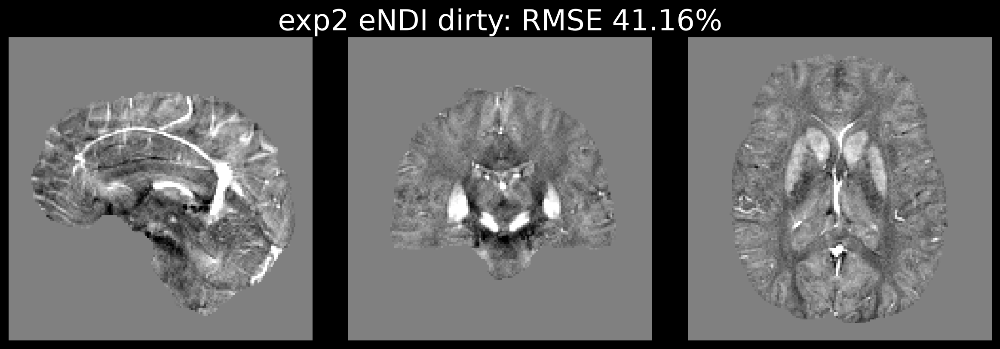

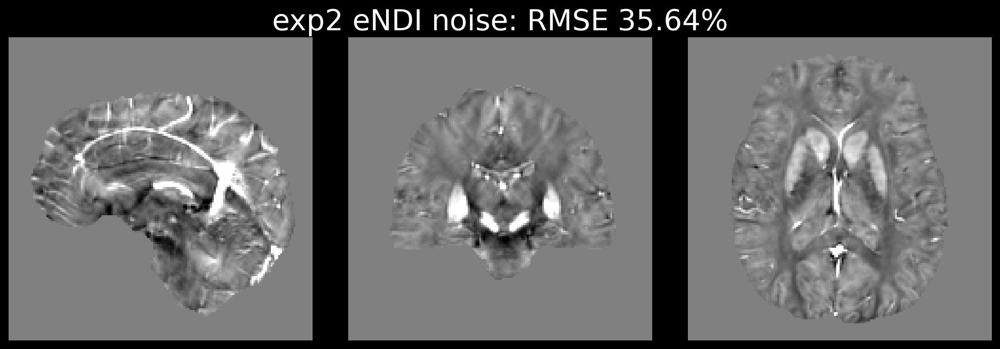

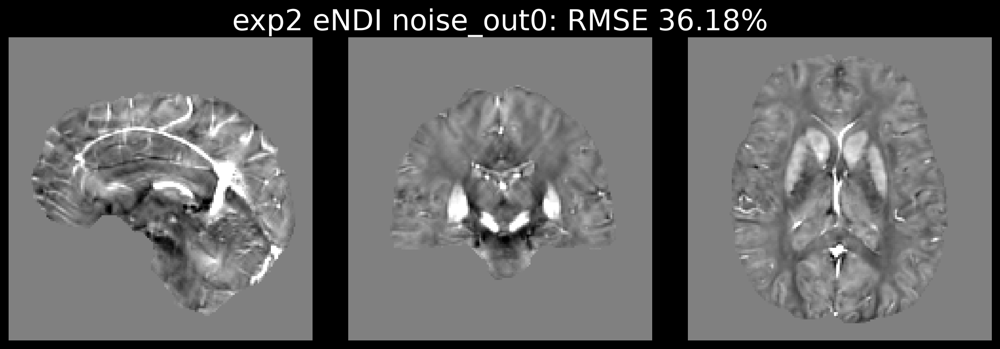

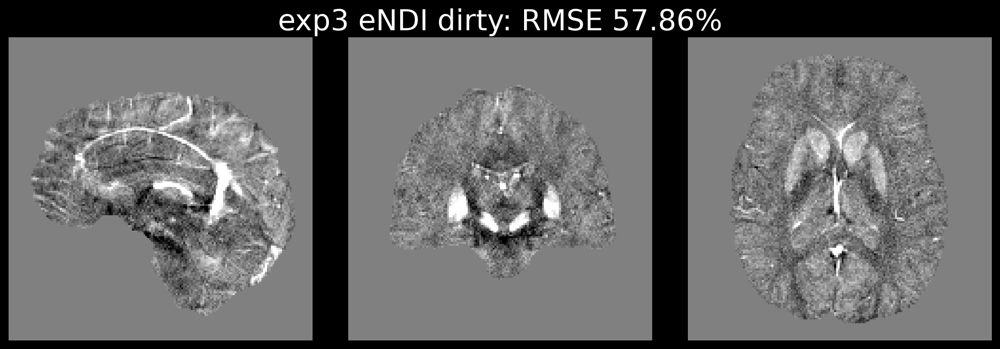

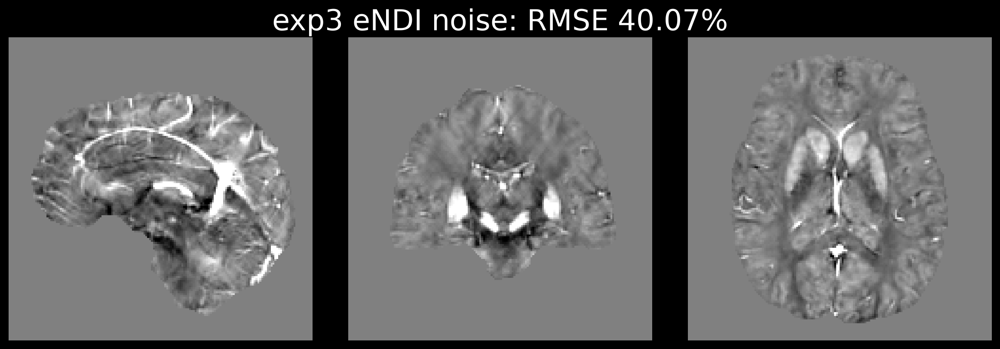

...

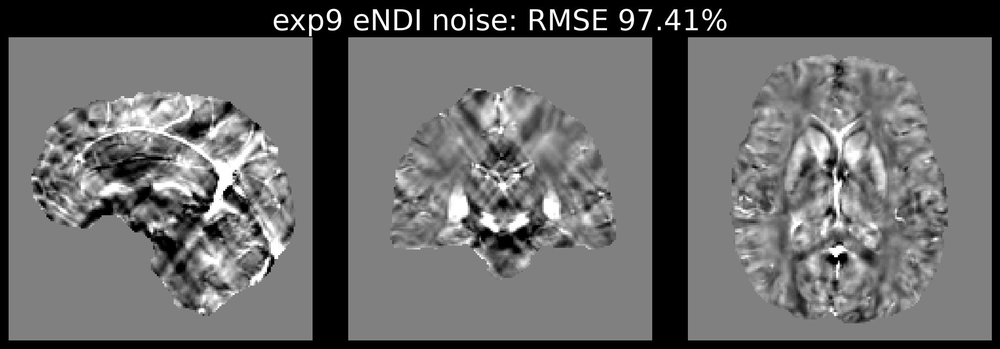

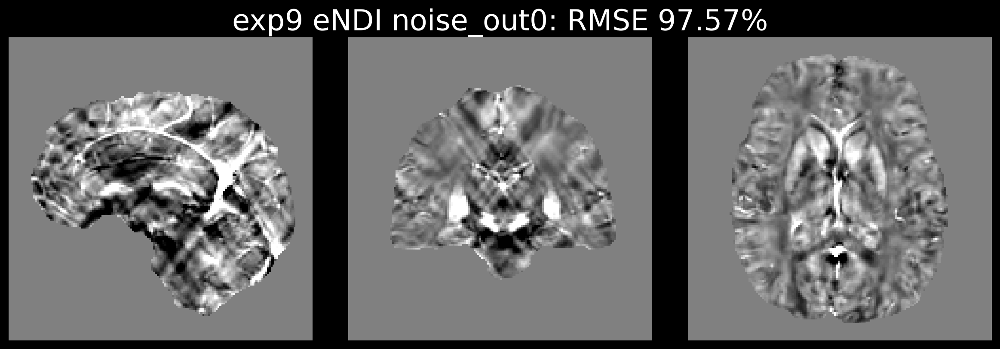

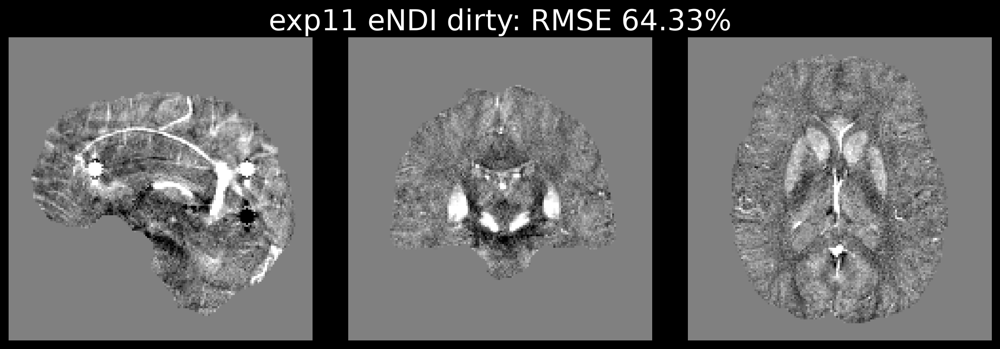

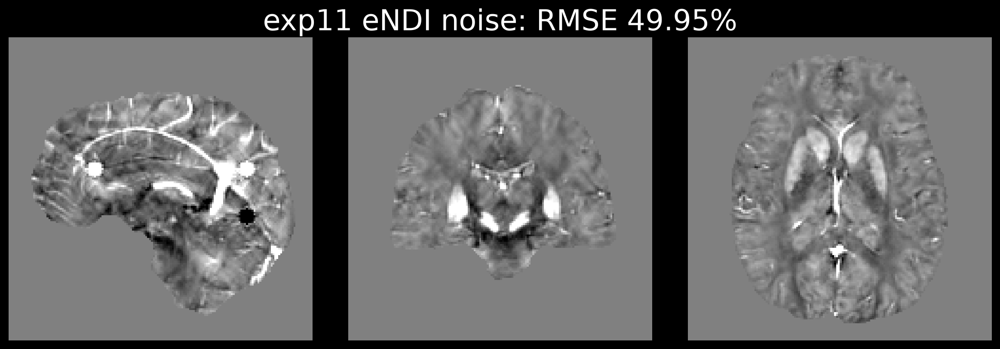

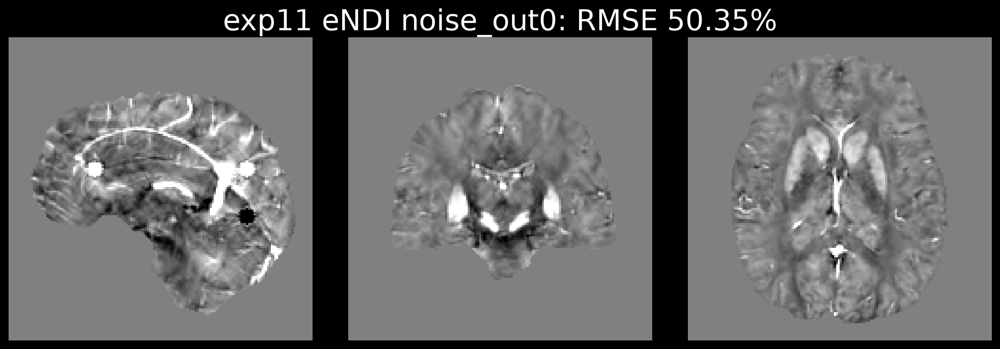

In [6]:
if "rc1" in SETS:
    for e in EXPS_RC1:
        d = load_exp("rc1", e)
        for m in meta[e]["methods"]:
            if f"chi_{m}" in d:
                view(d[f"chi_{m}"] * mask, f"{e} eNDI {m}: RMSE {compute_rmse(d[f'chi_{m}'] * mask, chi_gt * mask):.2f}%", CHI, ROT_RC1)

## B. Sim2 ground truth, forward-simulated

`chi` of Sim2 -> `D*chi` -> complex noise (the notebook recipe, the magnitude being the eNDI weight scaled to [0,1]) at SNR 100, 40, and at the SNR that reproduces the rms of the real Sim2 `psi` (0.0037 ppm); then two variants with phase jumps and with spheres in `chi` (as exp4 / exp11). The head was never trained on.

In [7]:
if "sim2" in SETS:
    table("sim2", "all")

phase NRMSE (%) vs mask*D*chi, region = all
experiment           dirty       noise  noise_out0         mix    mix_out0
sim2_snr100          21.44       16.97       17.65       23.60       24.01
sim2_snr40           34.10       19.44       20.09       25.63       26.08
sim2_snrcal          42.86       22.54       23.15       26.97       27.43
sim2_jumps           61.62       23.25       23.83       27.22       27.69
sim2_spheres         49.20       31.89       32.32       27.69       28.14

eNDI NRMSE (%) vs chi ground truth   (oracle mask*D*chi: 44.22%)
experiment           dirty       noise  noise_out0         mix    mix_out0
sim2_snr100          47.39       45.89       42.78         nan         nan
sim2_snr40           55.38       47.21       44.19         nan         nan
sim2_snrcal          60.40       48.27       45.90         nan         nan
sim2_jumps           60.53       49.76       49.47         nan         nan
sim2_spheres         63.85       52.33       50.62         nan   

sim2_snr100 forward-simulated, SNR 100


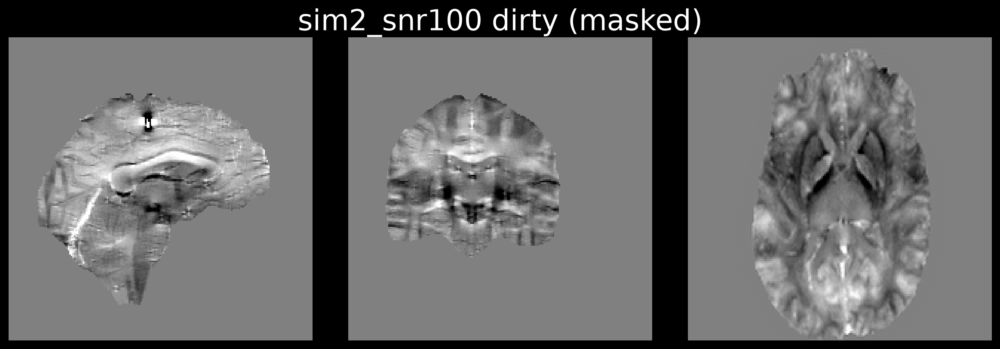

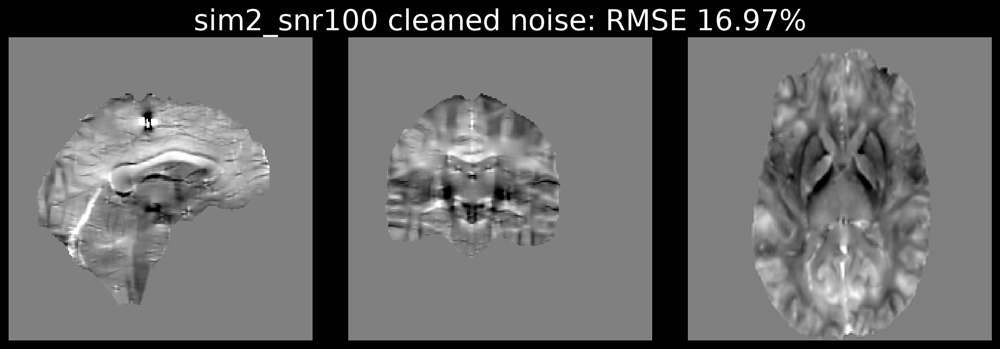

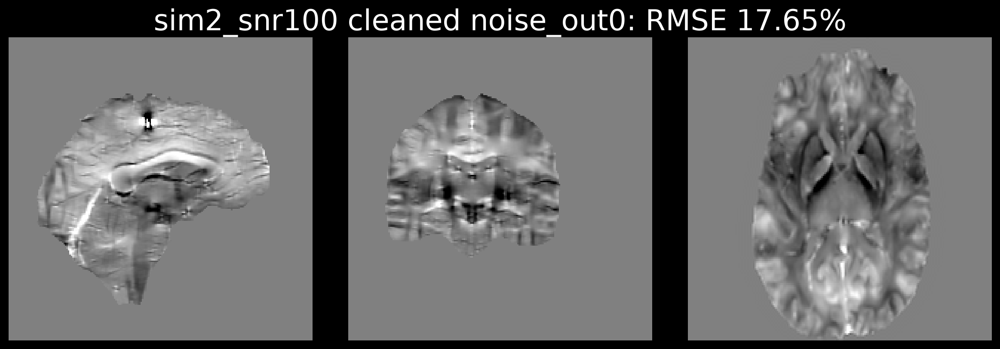

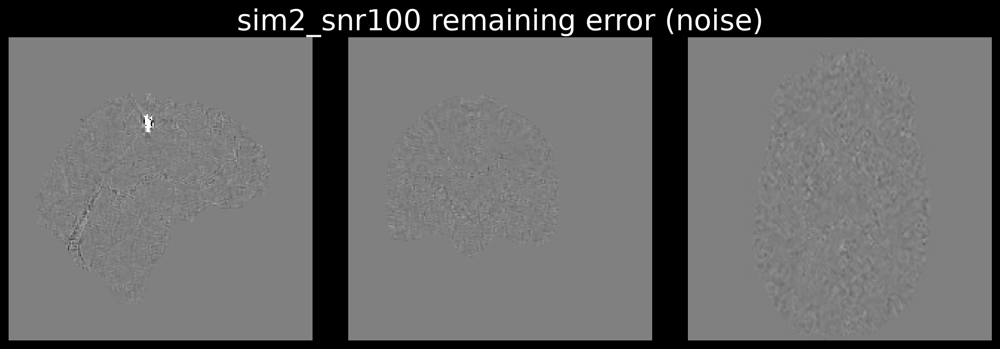

sim2_snr40 forward-simulated, SNR 40


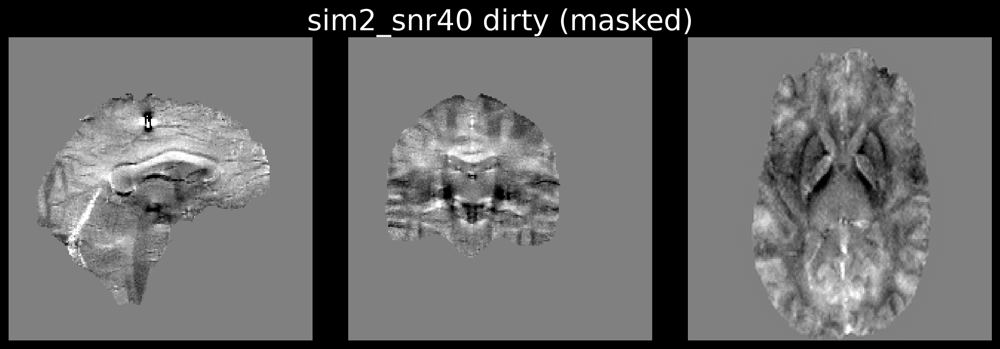

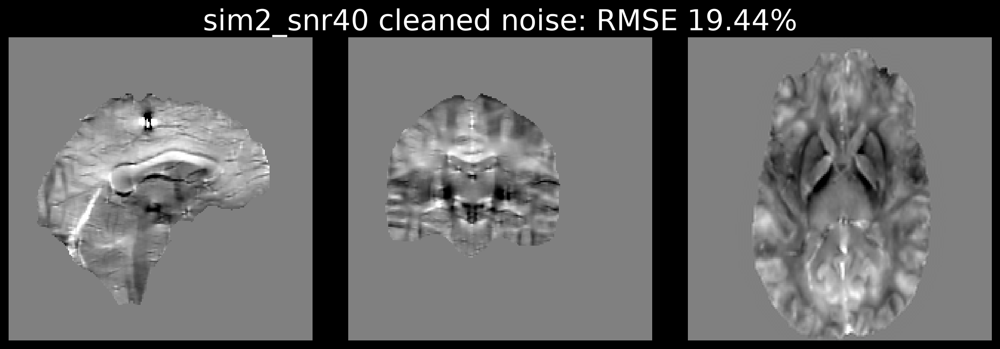

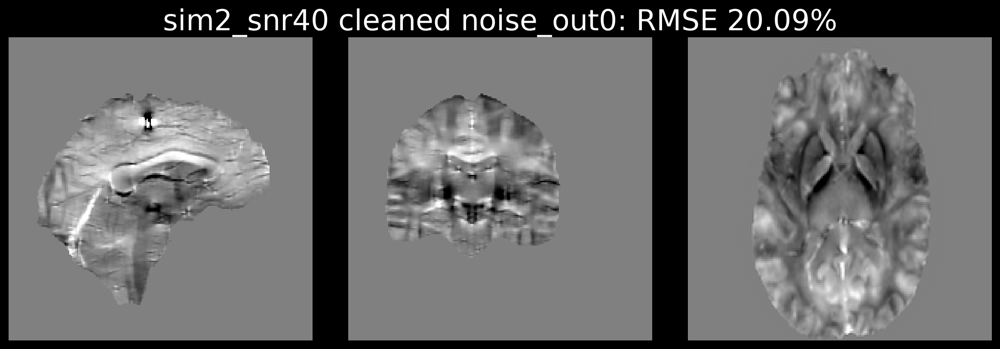

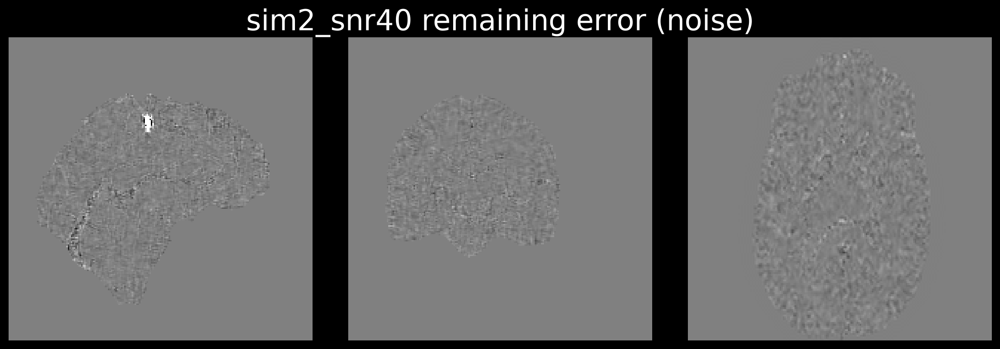

sim2_snrcal forward-simulated, SNR 30 (psi rms of Sim2)


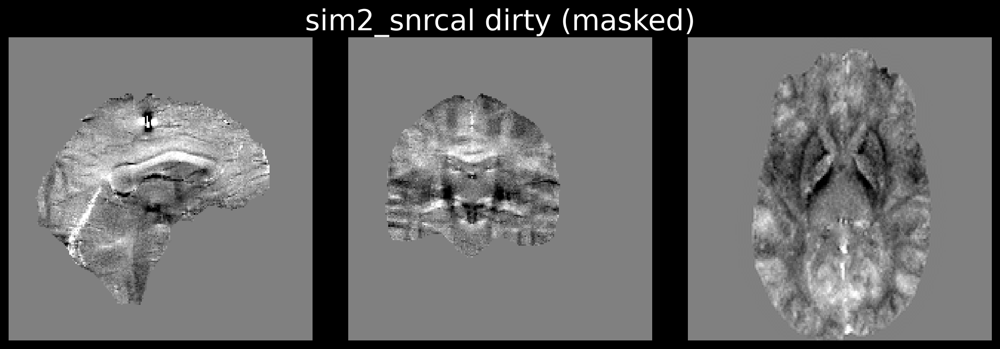

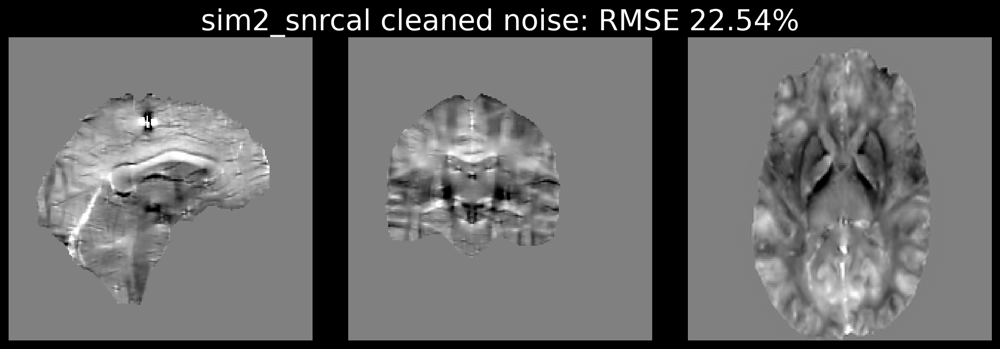

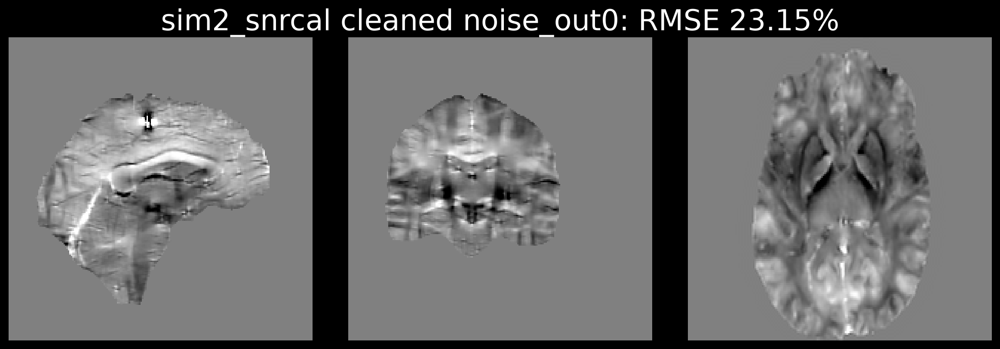

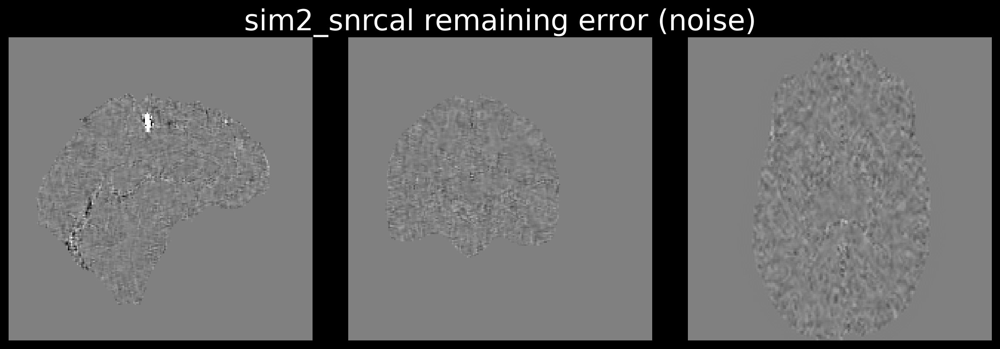

sim2_jumps SNR-cal noise + phase jumps


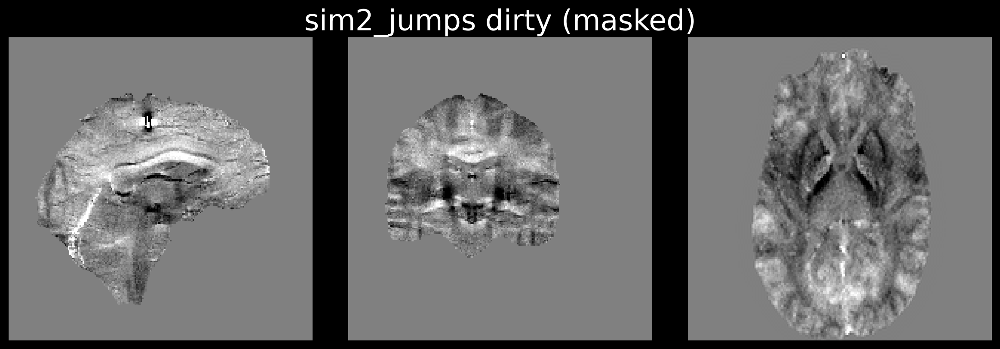

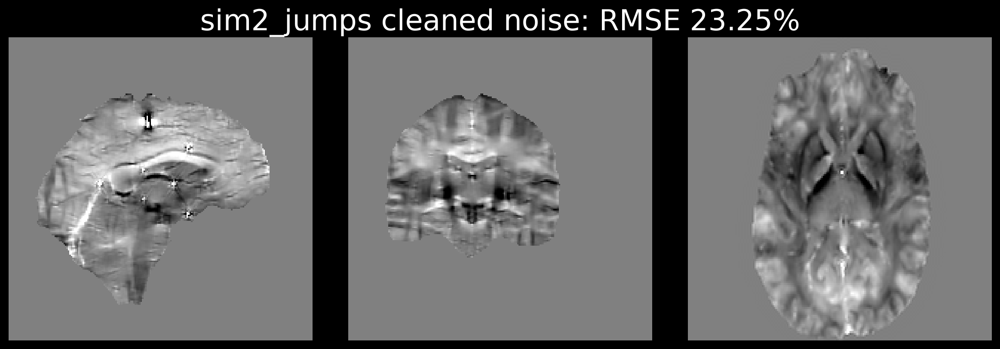

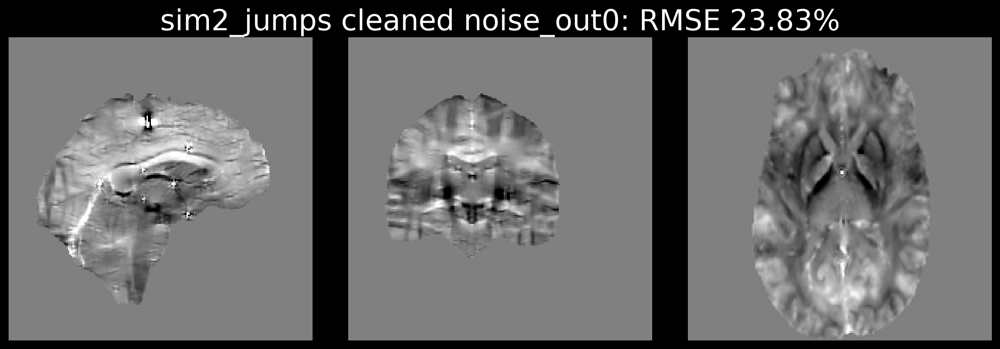

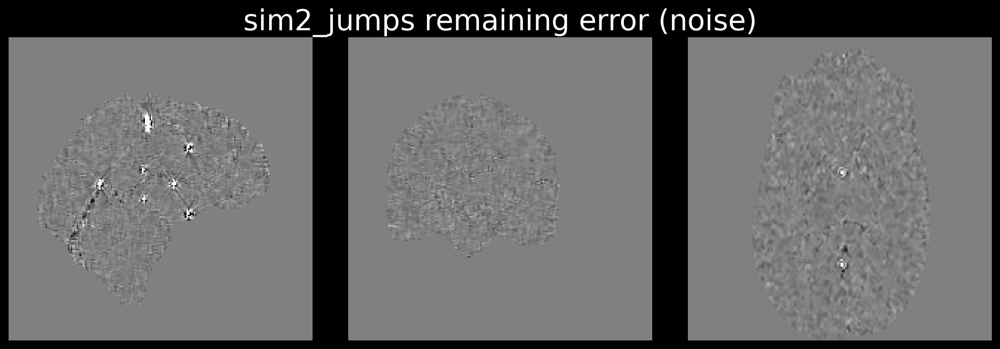

sim2_spheres SNR-cal noise + spheres in chi


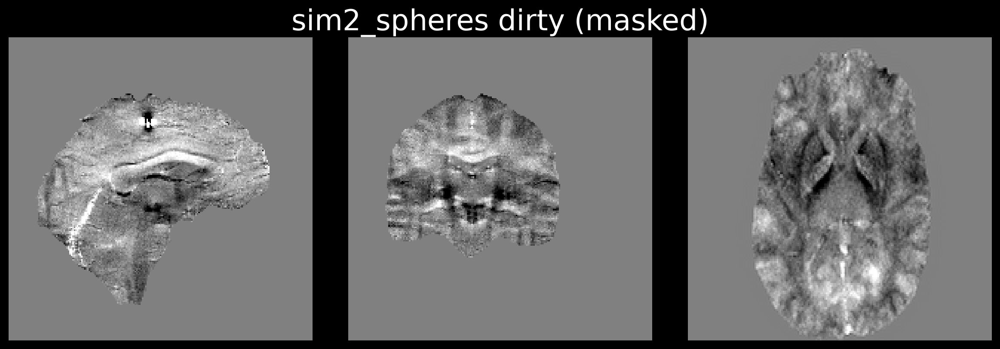

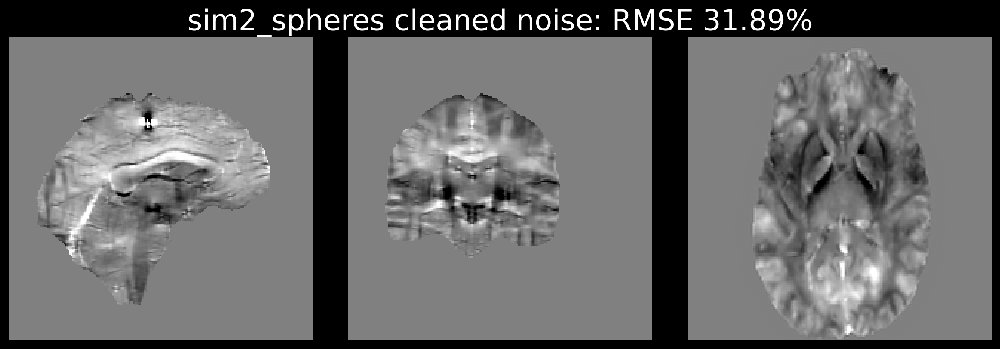

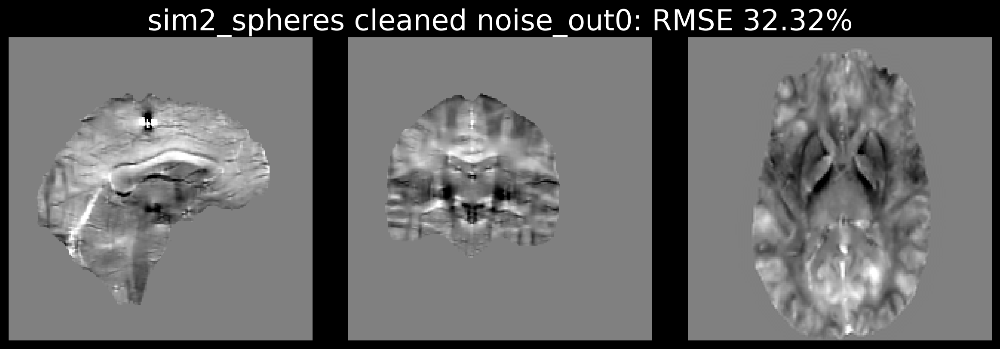

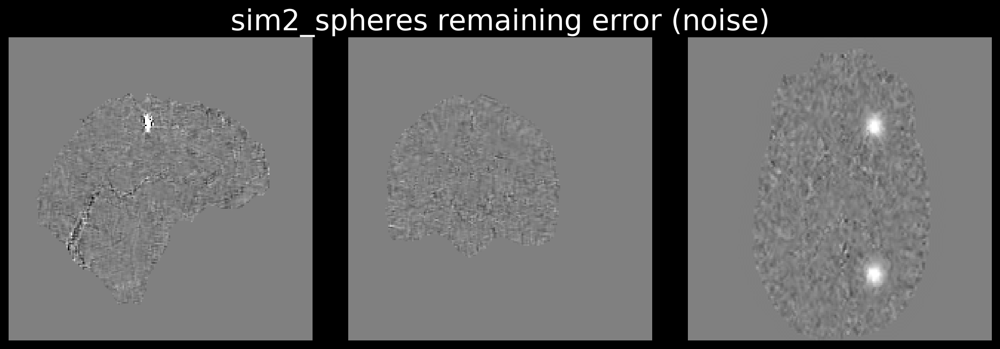

In [8]:
EXPS_SIM2 = ["sim2_snr100", "sim2_snr40", "sim2_snrcal", "sim2_jumps", "sim2_spheres"]
if "sim2" in SETS:
    common2, meta2 = SETS["sim2"]
    mask2, clean2, chi2 = common2["mask"], common2["clean"], common2["chi_gt"]
    target2 = clean2 * mask2
    for e in EXPS_SIM2:
        if e not in meta2:
            continue
        d = load_exp("sim2", e)
        print(e, meta2[e]["description"])
        view(d["field_dirty"], f"{e} dirty (masked)", FIELD, ROT_SIM2)
        for m in (MAIN, MAIN + "_out0"):
            if f"field_{m}" in d:
                view(d[f"field_{m}"], f"{e} cleaned {m}: RMSE {compute_rmse(d[f'field_{m}'], target2):.2f}%", FIELD, ROT_SIM2)
        view((d[f"field_{MAIN}"] - target2), f"{e} remaining error ({MAIN})", ERR, ROT_SIM2)

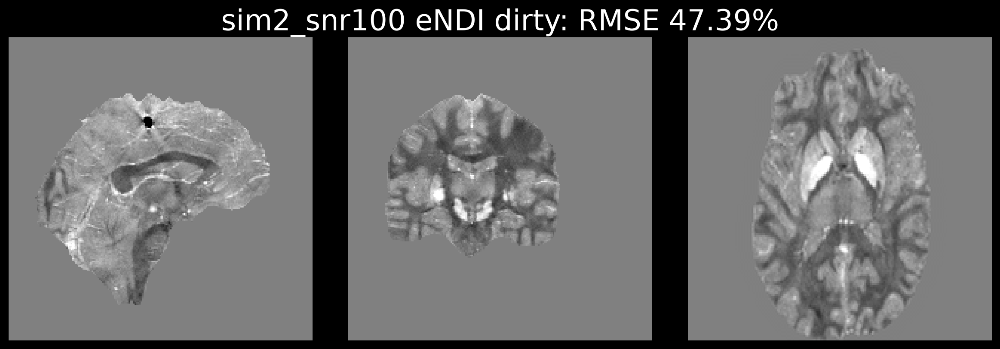

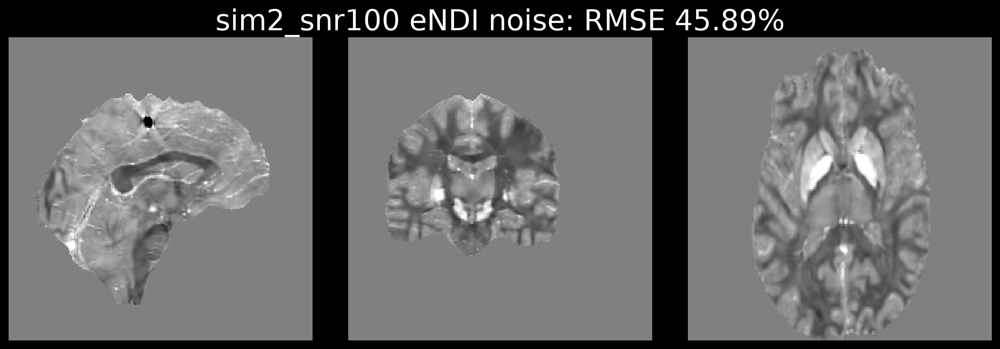

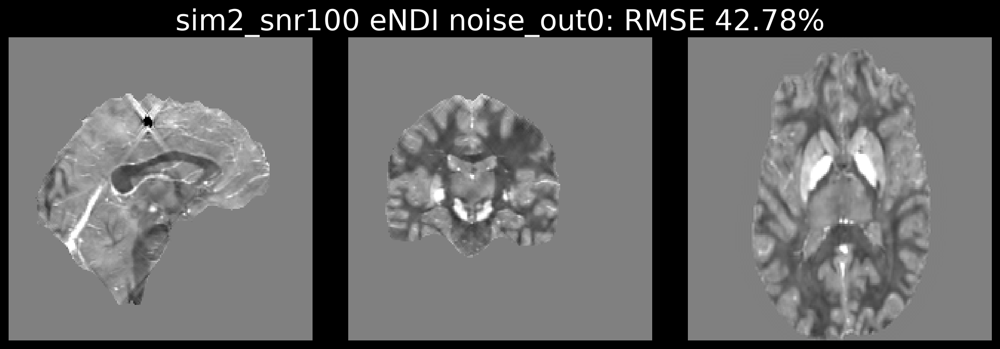

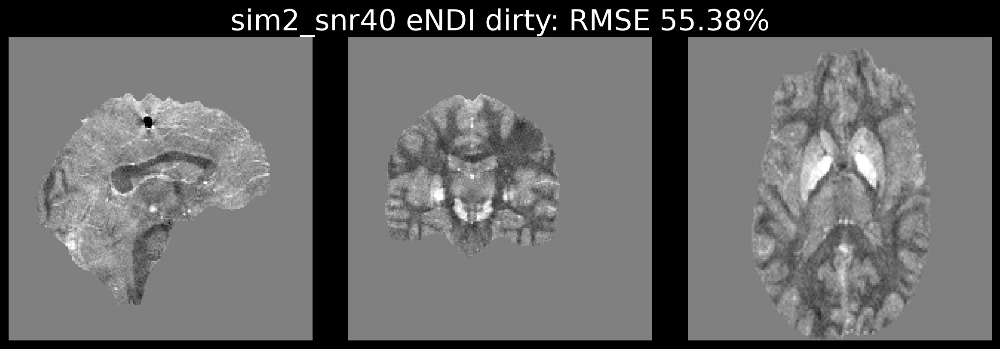

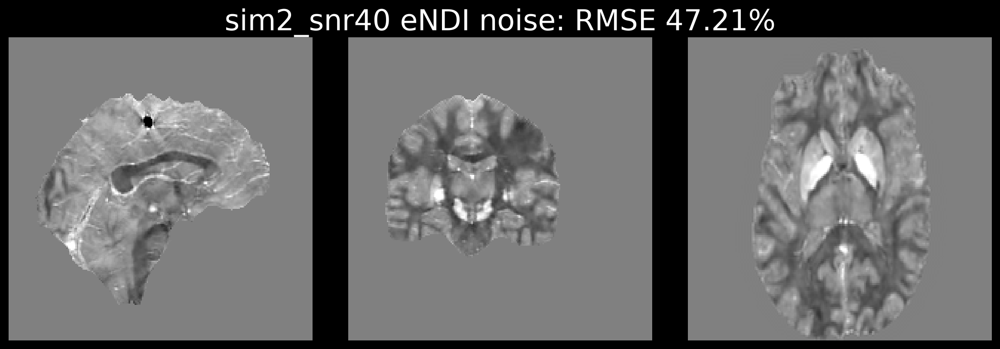

...

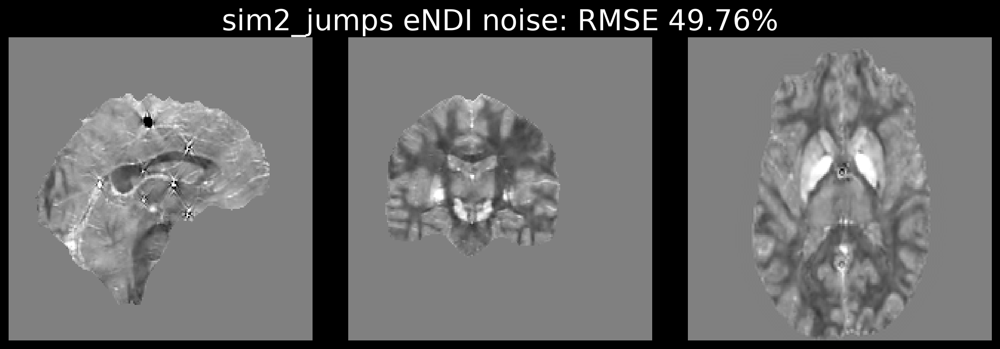

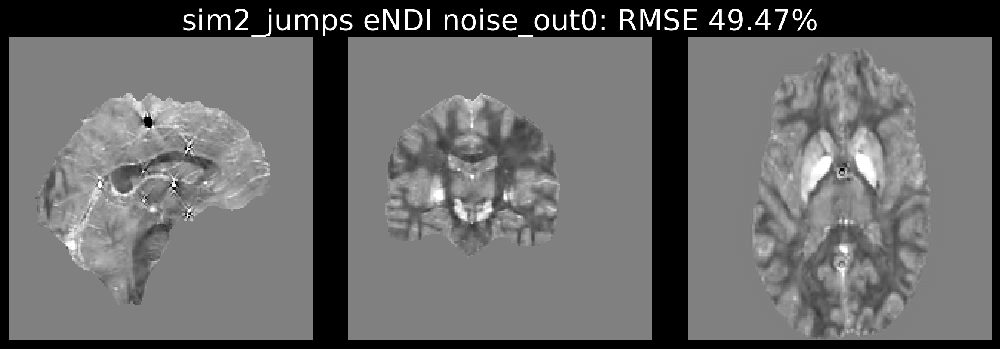

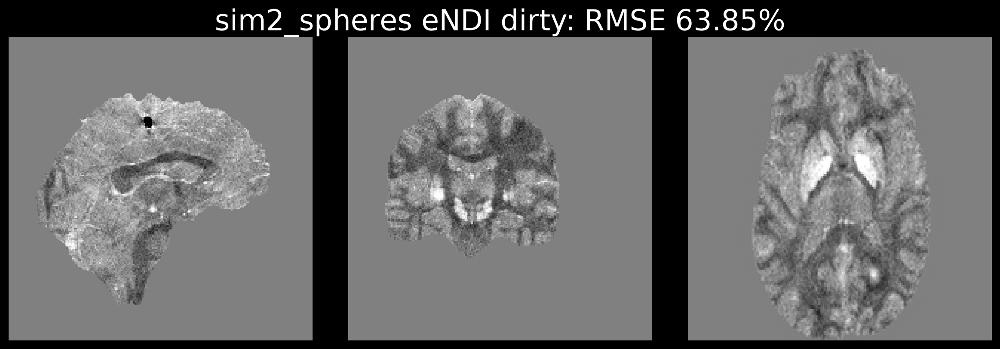

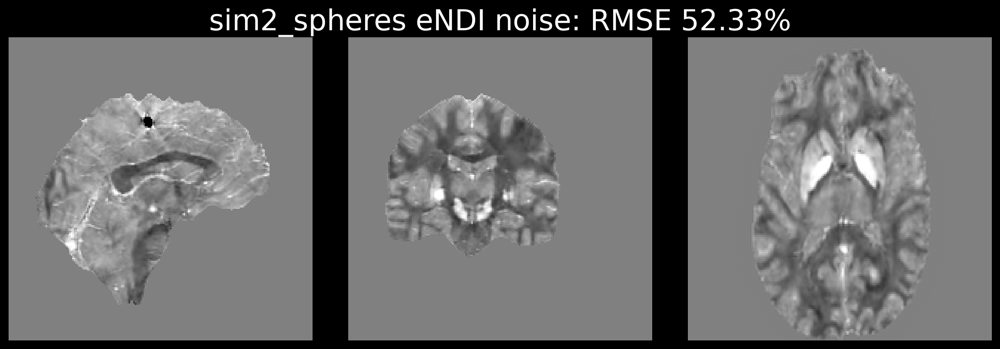

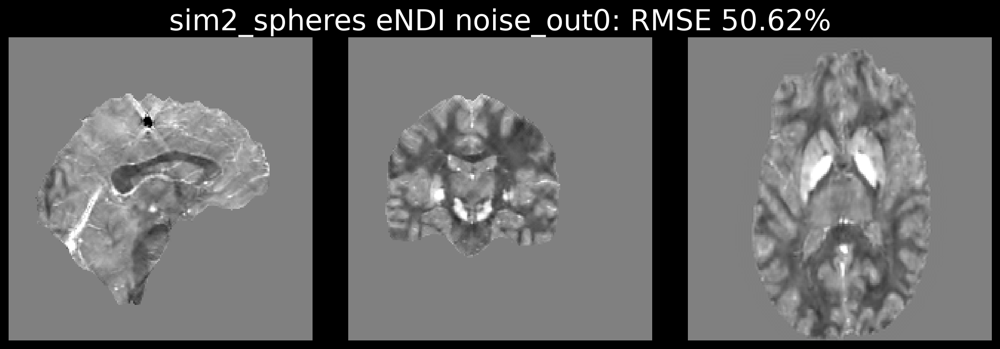

In [9]:
if "sim2" in SETS:
    for e in EXPS_SIM2:
        if e not in meta2:
            continue
        d = load_exp("sim2", e)
        for m in meta2[e]["methods"]:
            if f"chi_{m}" in d:
                view(d[f"chi_{m}"] * mask2, f"{e} eNDI {m}: RMSE {compute_rmse(d[f'chi_{m}'] * mask2, chi2 * mask2):.2f}%", CHI, ROT_SIM2)

## C. Does the net use the field outside the mask?

For each experiment: phase NRMSE of the cleaned field with `clean` outside (training convention) against `out0` (zeros outside). If `out0` is clearly worse, the nets rely on information that real data do not have, and the Sim2 results (whose outside field is zero) are pessimistic for the trained recipe; retraining with zeros outside would be the fix.

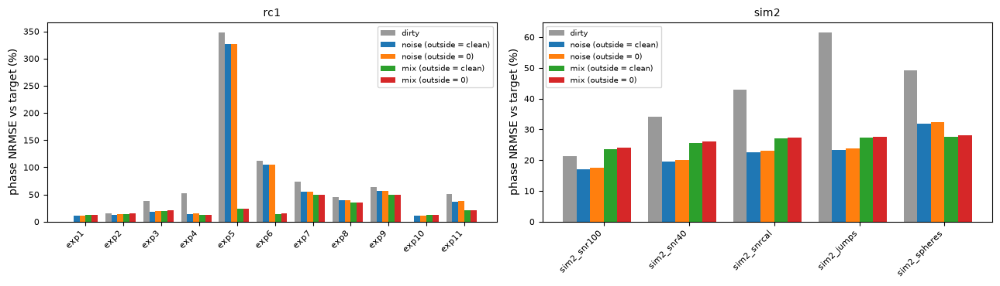

In [10]:
fig, axes = plt.subplots(1, len(SETS), figsize=(6.5 * len(SETS), 3.8), squeeze=False)
for ax, (tag, (cm, mt)) in zip(axes[0], SETS.items()):
    exps = [k for k in mt if k != "oracle"]
    runs = [m for m in mt[exps[0]]["methods"] if m != "dirty" and not m.endswith("_out0")]
    w = 0.8 / (1 + 2 * len(runs))
    x = np.arange(len(exps))
    ax.bar(x, [mt[e]["methods"]["dirty"]["phase_nrmse_all"] for e in exps], w, label="dirty", color="0.6")
    for i, r in enumerate(runs):
        ax.bar(x + (1 + 2 * i) * w, [mt[e]["methods"][r]["phase_nrmse_all"] for e in exps], w, label=f"{r} (outside = clean)")
        ax.bar(x + (2 + 2 * i) * w, [mt[e]["methods"][r + "_out0"]["phase_nrmse_all"] for e in exps], w, label=f"{r} (outside = 0)")
    ax.set_xticks(x + 0.4); ax.set_xticklabels(exps, rotation=45, ha="right")
    ax.set_ylabel("phase NRMSE vs target (%)"); ax.set_title(tag); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## D. The streaking source: zoom on the strongest susceptibility source of Sim2

The most extreme susceptibility voxel inside the mask is taken as the centre (check it is the calcification you mean; otherwise set `POS` by hand). The three planes of every inversion are shown through that point.

strongest |chi| in the mask at (82, 93, 148) value -2.03 ppm


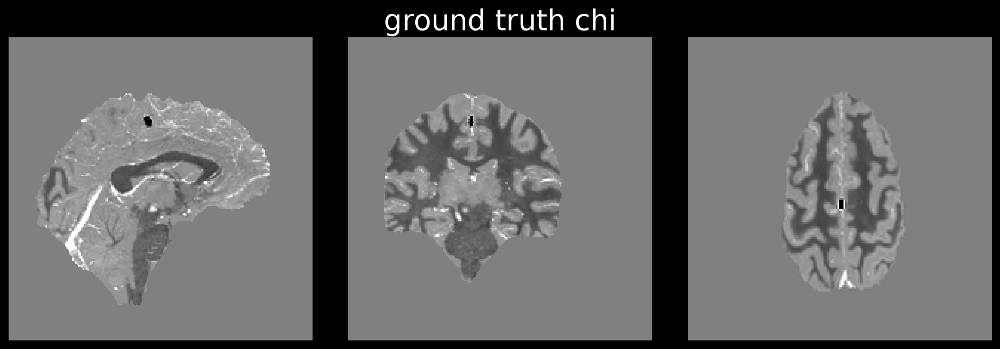

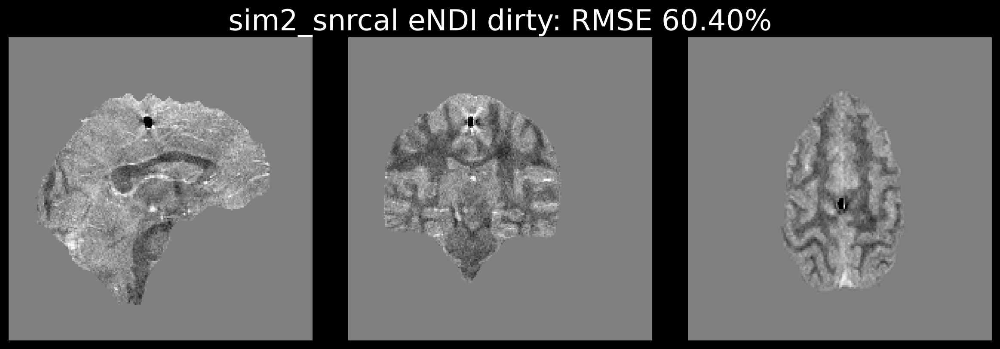

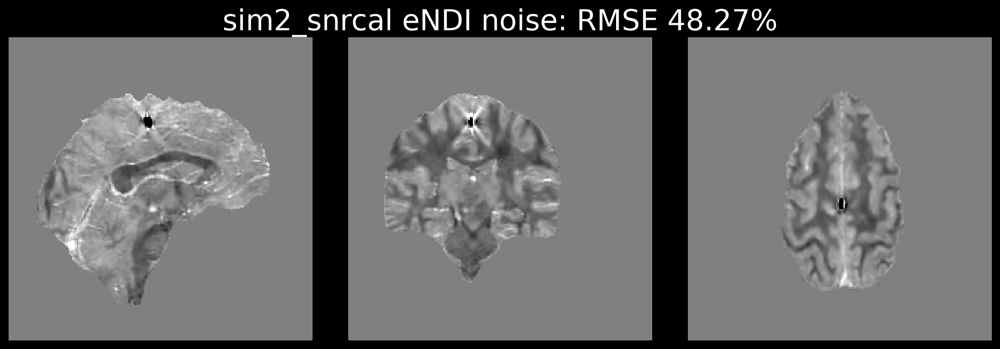

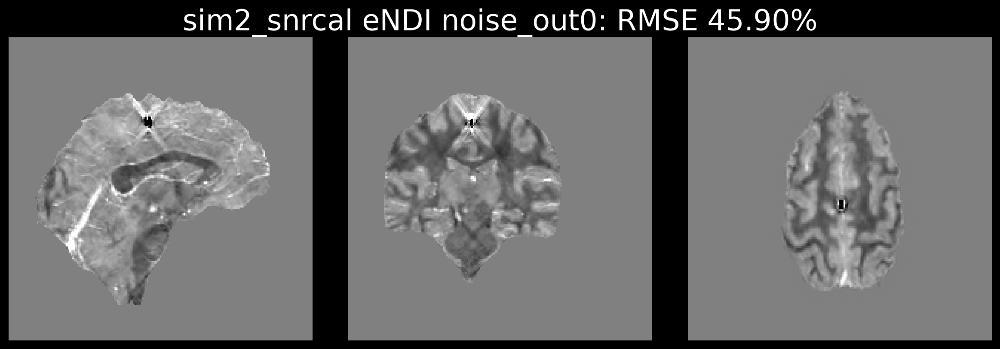

In [11]:
if "sim2" in SETS:
    inside = np.where(mask2 > 0, chi2, 0)
    POS = tuple(int(v) for v in np.unravel_index(np.argmax(np.abs(inside)), inside.shape))   # or set by hand
    print("strongest |chi| in the mask at", POS, "value %.2f ppm" % inside[POS])
    e = "sim2_snrcal"
    d = load_exp("sim2", e)
    view(chi2 * mask2, "ground truth chi", CHI, ROT_SIM2, pos=POS)
    for m in meta2[e]["methods"]:
        if f"chi_{m}" in d:
            view(d[f"chi_{m}"] * mask2, f"{e} eNDI {m}: RMSE {compute_rmse(d[f'chi_{m}'] * mask2, chi2 * mask2):.2f}%", CHI, ROT_SIM2, pos=POS)

## Reading guide

* RC1 numbers are in-sample for the head: they say whether the net does what it was trained for, not that it generalizes.
* The forward-simulated Sim2 says whether the *noise* denoiser transfers to an unseen head with a purely synthetic `psi`; it does not say anything about real artifacts (the real Sim2 result is in `s4b_results_visualization.ipynb`).
* Single seed per run, single volume per set.